In [1]:
import pandas as pd
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
train = pd.read_csv("../data/store_item_demand/train.csv")

In [3]:
test = pd.read_csv("../data/store_item_demand/test.csv")

In [4]:
train.shape

(913000, 4)

In [5]:
test.shape

(45000, 4)

In [6]:
train.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [7]:
test.head()

,id,date,store,item
0,0,2018-01-01,1,1
1,1,2018-01-02,1,1
2,2,2018-01-03,1,1
3,3,2018-01-04,1,1
4,4,2018-01-05,1,1


In [8]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 27.9 MB


In [9]:
train.isnull().sum()

date     0
store    0
item     0
sales    0
dtype: int64

In [10]:
train.duplicated().sum()

np.int64(0)

In [11]:
train["date"].min()

'2013-01-01'

In [12]:
train["date"].max()

'2017-12-31'

In [13]:
train["store"].nunique()

10

In [14]:
train.item.nunique()

50

In [15]:
minimum = train["sales"].min()
maximum = train["sales"].max()

train["scaled"] = (train["sales"] - minimum) / (maximum - minimum)

In [16]:
import numpy as np

LOOK_BACK = 30
TEST_DAYS = 30


In [17]:
def create_sequences(data):
    windows = np.lib.stride_tricks.sliding_window_view(
        data, LOOK_BACK + 1
    )
    return windows[:, :-1], windows[:, -1]


In [18]:
X_train,y_train = [],[]
X_val,y_val = [],[]

In [19]:
for _, group in train.groupby(["store", "item"]):

    sales = group.sort_values("date")["scaled"].values

    X, y = create_sequences(sales[:-TEST_DAYS])
    X_train.extend(X)
    y_train.extend(y)

    val_data = np.concatenate([sales[-TEST_DAYS-LOOK_BACK:-TEST_DAYS],
                               sales[-TEST_DAYS:]])

    X, y = create_sequences(val_data)
    X_val.extend(X)
    y_val.extend(y)

X_train = np.array(X_train).reshape(-1, LOOK_BACK, 1)
y_train = np.array(y_train)

X_val = np.array(X_val).reshape(-1, LOOK_BACK, 1)
y_val = np.array(y_val)

In [20]:
model = Sequential([
    tf.keras.Input(shape=(LOOK_BACK, 1)),
    LSTM(32),
    Dropout(0.2),
    Dense(1)
])

In [21]:
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# 6. Train model
model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    verbose=1
)


Epoch 1/15
13797/13797 ━━━━━━━━━━━━━━━━━━━━ 76s 5ms/step - loss: 0.0019 - mae: 0.0333 - val_loss: 0.0019 - val_mae: 0.0330
Epoch 2/15
13797/13797 ━━━━━━━━━━━━━━━━━━━━ 89s 6ms/step - loss: 0.0015 - mae: 0.0300 - val_loss: 0.0016 - val_mae: 0.0301
Epoch 3/15
13797/13797 ━━━━━━━━━━━━━━━━━━━━ 89s 6ms/step - loss: 0.0015 - mae: 0.0293 - val_loss: 0.0015 - val_mae: 0.0295
Epoch 4/15
13797/13797 ━━━━━━━━━━━━━━━━━━━━ 82s 6ms/step - loss: 0.0014 - mae: 0.0289 - val_loss: 0.0015 - val_mae: 0.0293
Epoch 5/15
13797/13797 ━━━━━━━━━━━━━━━━━━━━ 81s 6ms/step - loss: 0.0014 - mae: 0.0287 - val_loss: 0.0014 - val_mae: 0.0288
Epoch 6/15
13797/13797 ━━━━━━━━━━━━━━━━━━━━ 80s 6ms/step - loss: 0.0014 - mae: 0.0286 - val_loss: 0.0016 - val_mae: 0.0304
Epoch 7/15
13797/13797 ━━━━━━━━━━━━━━━━━━━━ 79s 6ms/step - loss: 0.0014 - mae: 0.0285 - val_loss: 0.0015 - val_mae: 0.0299
Epoch 8/15
13797/13797 ━━━━━━━━━━━━━━━━━━━━ 81s 6ms/step - loss: 0.0014 - mae: 0.0284 - val_loss: 0.0016 - val_mae: 0.0304
Epoch 9/15
13797

In [27]:
pred = model.predict(X_val, verbose=0).flatten()

actual = y_val * (maximum - minimum) + minimum
pred = pred * (maximum - minimum) + minimum

print("MAE:", mean_absolute_error(actual, pred))
print("RMSE:", np.sqrt(mean_squared_error(actual, pred)))

MAE: 6.745685690787434
RMSE: 8.983167110248782


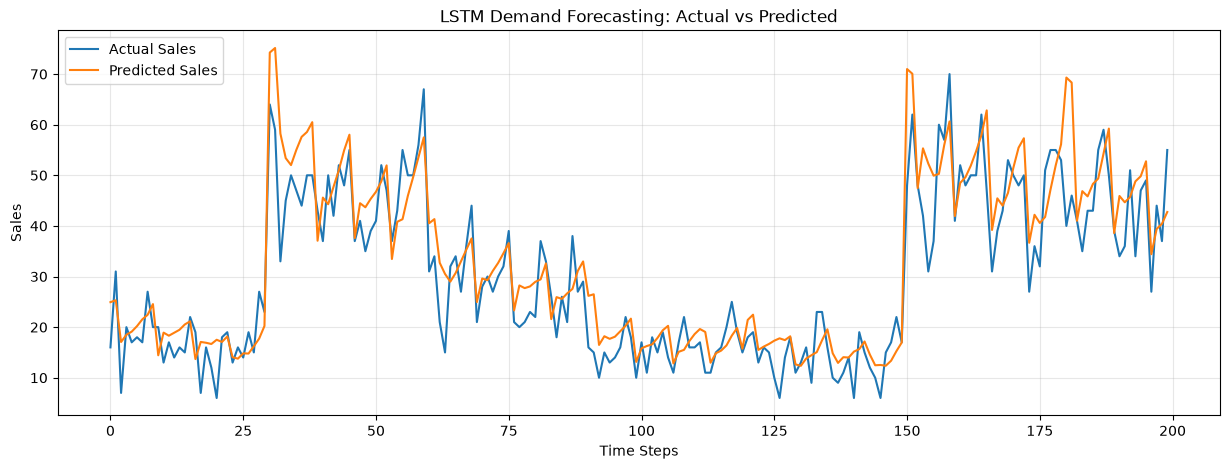

In [28]:
plt.figure(figsize=(15, 5))

plt.plot(actual[:200], label="Actual Sales")
plt.plot(pred[:200], label="Predicted Sales")

plt.title("LSTM Demand Forecasting: Actual vs Predicted")
plt.xlabel("Time Steps")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [33]:
submission = test.copy()
submission["sales"] = 0.0

for (store, item), indices in test.groupby(["store", "item"]).groups.items():

    history = train[
        (train["store"] == store) &
        (train["item"] == item)
    ].sort_values("date")["scaled"].values

    window = history[-LOOK_BACK:].reshape(1, LOOK_BACK, 1)

    prediction = model.predict(window, verbose=0)[0][0]

    submission.loc[indices, "sales"] = (
        prediction * (maximum - minimum) + minimum
    )

submission["sales"] = submission["sales"].clip(lower=0)


submission.to_csv("../data/store_item_demand/submission_lstm.csv", index=False)

In [34]:
model.save("../models/demand_lstm.keras")